# FASE 1 - Métricas de comportamiento por evento

Este notobook complementa los alcances de la Fase 1, luego de generar las capas necesarias para los calculos. 

### **¿Que hace?

convierte cada polígono del inventario en medidas de su comportamiento. Con el DEM calcula el desnivel H, la distancia horizontal L y el índice de movilidad H/L de cada evento, marca los eventos cuyas medidas no son confiables y revisa la colinealidad entre las variables candidatas del vector de comportamiento. Con ese resultado se definió el vector que usan las fases siguientes: el $log_{10}$ del área, del H/L y de la elongación.

Las medidas de cada evento se definen de la siguiente forma:

|Medida|Descripción|
|--|--|
|Corona|celda del DEM más alta cuyo centro cae dentro del polígono|
|Pie|celda del DEM más baja cuyo centro cae dentro del polígono|
|H|Cota de la corona menos cota del pie, en metros|
|L|Distancia horizontal en línea recta entre el centro de la celda de la corona y el de la celda del pie, en metros|
|H/L|Índice de movilidad, sin unidades. Es la tangente del ángulo de alcance: entre menor sea, más lejos llegó el material por cada metro que descendió|


### **SALIDAS**

Este código entrega diferentes archivos para su uso en fases posteriores y para entregar la información recopilada fuera de la consola. 

Las capas `fase1_movilidad` y `fase1_linea_corona_pie` se generan dentro de la geodatabase del proyecto, la primera copia del inventario con las medidas de cada evento más la elongación, los logaritmos y el campo `USO_METRICAS`, y la segunda genera una línea de la corona al pie por evento, para revisar en el mapa.

#### **¿Cómo reproducirlo?**

Este código fue creado en Notebooks de ArcGIS PRO, por lo que se sugiere su uso dentro del software, el proyecto debe contener la capa con el inventario integrado y el DEM recortado a cada polígono. 

1. Si las calas del DEM recortado y del inventario integrado no están en el mapa, poner en la celda 3 la ruta completa de cada una.
2. Por defecto la variable `GDB_SALIDA = None` por lo que los resultados quedan en la geodatabase predeterminada del proyecto.
3. Ejecutar las celdas 1 a 11 en orden.
4. Calcular la elongación y los logaritmos en la tabla de atributos de `fase1_movilidad` 




# -----------------------------------------------------------------------------
# BLOQUE 0. LIBRERÍAS
# Carga las herramientas que usa el código. Todas vienen instaladas con
# ArcGIS Pro; no hay que instalar nada.
# -----------------------------------------------------------------------------

In [16]:

import os
import numpy as np
import arcpy
import math 

# BLOQUE 1. Parámetros

**¿Que hace?**

Reúne lo que se puede cambiar: las capas de entrada, dónde se guardan los resultados, los nombres de las capas nuevas y el mínimo de celdas para confiar en las medidas.


In [27]:
 
INVENTARIO = r"Inventario_integrado"   # Capa de polígonos del inventario

DEM_POLIGONOS = r"DEM_extract_pol"  # Modelo digital de elevación recortado a cada polígono

GDB_SALIDA = None    # Geodatabase donde se guardan los resultados (se crea si no existe)


CAPA_SALIDA = "fase1_movilidad"    # Nombre de la copia del inventario que recibirá los resultados


CAPA_LINEAS = "fase1_linea_corona_pie"    # Nombre de la capa de líneas corona-pie (sirve para el control de calidad)


CAMPO_ID = "ID_evento"   # Nombre exacto de la columna que identifica cada evento


MIN_CELDAS = 10     # Mínimo de celdas del DEM dentro de un polígono para confiar en H y L

CAPA_CORONAS= None   # Puntos que reprecentan el centro de la celda de más altura del poligono

# BLOQUE 2. Funciones de apoyo

**¿Que hace?**

Define tres funciones que el bloque 8 aplica a cada polígono:

* `leer_anillos` saca las coordenadas de los bordes del polígono
* `puntos_en_poligono` decide qué centros de celda caen dentro del polígono
* `leer_bloque` lee del DEM solo el pedazo que cubre el polígono, con las coordenadas del centro de cada celda.

In [28]:
def leer_anillos(geom):
    """Convierte el polígono de ArcGIS en una lista de anillos de coordenadas.
    Un anillo es un contorno cerrado: el borde exterior o el borde de un hueco."""
    
    # Lista vacía donde se van guardando los anillos
    anillos = []
    
    for parte in geom:
        # Lista vacía para el anillo que se está leyendo
        actual = []
        # Recorre cada vértice de la parte
        for p in parte:
            # ArcGIS pone "None" entre el borde exterior y un hueco
            if p is None:
                # Guarda el anillo terminado (si tiene al menos 3 vértices)
                if len(actual) >= 3:
                    anillos.append(np.array(actual))
                # Empieza un anillo nuevo
                actual = []
            else:
                # Agrega la coordenada (X, Y) del vértice al anillo actual
                actual.append((p.X, p.Y))
        # Guarda el último anillo de la parte
        if len(actual) >= 3:
            anillos.append(np.array(actual))
    # Devuelve todos los anillos encontrados
    return anillos
 
 
def puntos_en_poligono(px, py, anillos):
    """Dice qué puntos caen dentro del polígono (Verdadero/Falso por punto)."""
    # Empieza suponiendo que ningún punto está adentro
    dentro = np.zeros(px.shape, dtype=bool)
    # Recorre cada anillo (borde exterior y huecos)
    for anillo in anillos:
        # Coordenadas del vértice inicial de cada lado del anillo
        xa, ya = anillo[:, 0], anillo[:, 1]
        # Coordenadas del vértice final de cada lado (el siguiente vértice)
        xb, yb = np.roll(xa, -1), np.roll(ya, -1)
        # Recorre cada lado del anillo
        for x1, y1, x2, y2 in zip(xa, ya, xb, yb):
            # Un lado horizontal no cruza la línea horizontal: se salta
            if y1 == y2:
                continue
            # Verdadero para los puntos cuya altura Y está entre los dos extremos del lado
            cruza = (y1 > py) != (y2 > py)
            # Coordenada X donde el lado corta la horizontal de cada punto
            x_corte = x1 + (py - y1) * (x2 - x1) / (y2 - y1)
            # Si el corte queda a la derecha del punto, cambia su estado adentro/afuera
            dentro ^= cruza & (px < x_corte)
            
    # Devuelve Verdadero/Falso para cada punto
    return dentro
 
 
def leer_bloque(extension):
    """Lee del ráster recortado solo el pedazo que cubre el polígono y calcula la
    coordenada del centro de cada celda. Devuelve None si no hay superposición."""
    
    # Primera columna del ráster que toca el polígono (sin salirse del ráster)
    c0 = max(0, int(np.floor((extension.XMin - X0) / DX)))
    
    # Última columna (+1) que toca el polígono
    c1 = min(NCOL, int(np.ceil((extension.XMax - X0) / DX)))
    
    # Primera fila, contada desde abajo, que toca el polígono
    f0 = max(0, int(np.floor((extension.YMin - Y0) / DY)))
    
    # Última fila (+1), contada desde abajo
    f1 = min(NFIL, int(np.ceil((extension.YMax - Y0) / DY)))
    
    # Si el polígono queda fuera del ráster, no hay nada que leer
    if c1 <= c0 or f1 <= f0:
        return None
        
    # Coordenada X de la esquina inferior izquierda del pedazo
    x_esq = X0 + c0 * DX
    
    # Coordenada Y de la esquina inferior izquierda del pedazo
    y_esq = Y0 + f0 * DY
    
    # Punto de lectura, desplazado 1 % de celda hacia adentro para evitar redondeos
    punto = arcpy.Point(x_esq + 0.01 * DX, y_esq + 0.01 * DY)
    
    # Lee las cotas del pedazo como una tabla de números (fila 0 = la de arriba)
    z = arcpy.RasterToNumPyArray(mde, punto, c1 - c0, f1 - f0, SIN_DATO).astype(float)
    
    # Las celdas sin dato se convierten en NaN ("no es un número") para ignorarlas
    z[z == SIN_DATO] = np.nan
    
    # Número de filas y columnas que realmente se leyeron
    nf, nc = z.shape
    
    # Coordenada X del centro de cada columna
    xc = x_esq + (np.arange(nc) + 0.5) * DX
    
    # Coordenada Y del centro de cada fila (de arriba hacia abajo)
    yc = y_esq + (nf - np.arange(nf) - 0.5) * DY
    
    # Crea las coordenadas X e Y de todas las celdas del pedazo
    xg, yg = np.meshgrid(xc, yc)
    
    # Devuelve las cotas y las coordenadas, como listas planas
    return z.ravel(), xg.ravel(), yg.ravel()

# BLOQUE 3. VERIFICACIONES INICIALES

**¿Que hace?**

Revisa que los datos estén listos antes de calcular y fija las rutas de las dos capas que crea el notebook. Si algo falla, se detiene y muestra un mensaje que indica qué corregir. No escribe nada.




In [29]:
# Permite que el código reemplace resultados de una ejecución anterior
arcpy.env.overwriteOutput = True
 
# Si no se indica una geodatabase de salida 
#usa la geodatabase predeterminada del proyecto abierto en ArcGIS Pro
if GDB_SALIDA is None:
    
    GDB_SALIDA = arcpy.mp.ArcGISProject("CURRENT").defaultGeodatabase
    
# Muestra dónde se van a guardar los resultados
print("Los resultados se guardarán en:", GDB_SALIDA)
 
# Lee el sistema de coordenadas del inventario
sr = arcpy.Describe(INVENTARIO).spatialReference

# Comprueba que sea un sistema proyectado (para poder hacer los calculos en metros)
if sr.type != "Projected":
    raise ValueError("El inventario está en grados. Reproyéctalo a "
                     "MAGNA-SIRGAS Origen Nacional con la herramienta Proyectar.")
 
# Obtiene la lista de nombres de columnas del inventario
campos = [f.name for f in arcpy.ListFields(INVENTARIO)]

# Comprueba que exista la columna de identificador
if CAMPO_ID not in campos:
    raise ValueError("No existe la columna " + CAMPO_ID + ". Columnas: " + ", ".join(campos))
 
# Abre el MDE recortado como objeto ráster de ArcGIS
mde = arcpy.Raster(DEM_POLIGONOS)

# Sistema de coordenadas del ráster
sr_mde = mde.spatialReference

# Compara los dos sistemas por su código EPSG; si alguno no lo tiene, por nombre
if sr_mde.factoryCode and sr.factoryCode:
    misma_referencia = sr_mde.factoryCode == sr.factoryCode
else:
    misma_referencia = sr_mde.name == sr.name
    
# Si no coinciden, detiene el código y explica el problema
if not misma_referencia:
    raise ValueError("El MDE recortado (" + sr_mde.name + ") y el inventario ("
                     + sr.name + ") están en sistemas de coordenadas distintos.")

Los resultados se guardarán en: C:\Users\villa\Documents\ArcGIS\Projects\GDB_proyecto de grado\GDB_proyecto de grado.gdb


# BLOQUE 4. Datos del ráster (DEM)

**¿Que hace?**

Guarda las propiedades del DEM que la función `leer_bloque` necesita para ubicar cada celda, e imprime el tamaño de celda para confirmarlo. 


In [30]:
#Coordenada X del borde izquierdo del ráster
X0 = mde.extent.XMin

# Coordenada Y del borde inferior del ráster
Y0 = mde.extent.YMin

# Ancho y alto de cada celda en metros 
DX = mde.meanCellWidth
DY = mde.meanCellHeight

# Número total de columnas y filas del ráster
NCOL = mde.width
NFIL = mde.height

# Valor con el que se marcarán las celdas sin dato
SIN_DATO = -99999 if mde.isInteger else -99999.0
 
# Muestra en pantalla el tamaño de celda, para confirmarlo
print("Tamaño de celda del MDE recortado:", round(DX, 2), "x", round(DY, 2), "m")

Tamaño de celda del MDE recortado: 2.0 x 2.0 m


# BLOQUE 5. Copia del inventario y campos nuevos

**¿Que hace?**

Copia el inventario completo, con todos sus campos, a la geodatabase de salida llamada `fase1_movilidad`, y agrégale los doce campos donde luego se escribirán los resultados. El inventario original no se modifica.

Si `fase1_movilidad` ya existe, esta celda la reemplaza y se pierden los campos que se le agregaron después


In [31]:
# Ruta completa de la copia del inventario
salida = os.path.join(GDB_SALIDA, CAPA_SALIDA)

# Copia el inventario (con todas sus columnas, incluida el área)
arcpy.management.CopyFeatures(INVENTARIO, salida)
 
# Lista de columnas nuevas: [nombre, tipo, alias, largo del texto]
columnas_nuevas = [
    ["N_CELDAS",  "LONG",   "Celdas con cota dentro del poligono", None],
    ["Z_CORONA",  "DOUBLE", "Cota de la corona (m)",               None],
    ["Z_PIE",     "DOUBLE", "Cota del pie (m)",                    None],
    ["H_M",       "DOUBLE", "Desnivel H (m)",                      None],
    ["L_M",       "DOUBLE", "Longitud horizontal L (m)",           None],
    ["H_L",       "DOUBLE", "Movilidad H/L",                       None],
    ["X_CORONA",  "DOUBLE", "X de la corona",                      None],
    ["Y_CORONA",  "DOUBLE", "Y de la corona",                      None],
    ["X_PIE",     "DOUBLE", "X del pie",                           None],
    ["Y_PIE",     "DOUBLE", "Y del pie",                           None],
    ["COBERTURA", "DOUBLE", "Area de celdas / area del poligono",  None],
    ["FLAG_MOV",  "TEXT",   "Calidad de la movilidad",             20],
]

# Agrega todas las columnas nuevas a la copia 
arcpy.management.AddFields(salida, columnas_nuevas)

<Result 'C:\\Users\\villa\\Documents\\ArcGIS\\Projects\\GDB_proyecto de grado\\GDB_proyecto de grado.gdb\\fase1_movilidad'>

# BLOQUE 6. Cálculo por evento 

**¿Que hace?**

Recorre los polígonos uno por uno. Para cada uno toma las celdas del DEM cuyo centro cae dentro, busca la más alta (corona) y la más baja (pie), calcula $H$, $L$ y $H/L$, califica el resultado y lo escribe en su fila de `fase1_movilidad`. También guarda los datos para dibujar la línea corona–pie posteriormente.


**Calificación de los eventos**


|Calificación|Condición|Qué significa|
|---|---|---|
|`POCAS_CELDAS`|Menos de 10 celdas (definido por `MIN_CELDAS`) |El polígono es muy pequeño o no tiene cota en el DEM|
|`REVISAR_RECORTES`|Cobertura menor que 0,67 o mayor que 1,5|El DEM no cubre bien el polígono.|
|`H_NULO`|H/L vacío|No hay desnivel dentro del polígono|
|`OK`|Ninguna de las anteriores|Medidas confiables|

In [32]:
# Columnas que se leen y escriben: forma, identificador y las 12 nuevas
lista_campos = ["SHAPE@", CAMPO_ID] + [c[0] for c in columnas_nuevas]

# Lista vacía donde se guardan los datos para dibujar las líneas corona-pie
lineas = []
 
# Abre la copia en modo edición, fila por fila
with arcpy.da.UpdateCursor(salida, lista_campos) as cursor:
    
    # Recorre cada fila (cada evento)
    for fila in cursor:
        # Separa la forma del polígono y su identificador
        geom, id_evento = fila[0], fila[1]
 
        # Valores por defecto: 0 celdas y todo lo demás vacío (None = nulo)
        n = 0
        zc = zp = H = L = HL = xc = yc = xp = yp = cobertura = None
 
        # Si el polígono tiene forma 
        if geom is not None:
            # Convierte el polígono en anillos de coordenadas
            anillos = leer_anillos(geom)
            # Lee el pedazo del ráster que cubre el polígono
            bloque = leer_bloque(geom.extent)
            # Si el polígono se superpone con el ráster...
            if bloque is not None:
                # Separa cotas y coordenadas de las celdas del pedazo
                z, x, y = bloque
                # Marca las celdas cuyo centro cae dentro del polígono y que tienen cota
                ok = puntos_en_poligono(x, y, anillos) & ~np.isnan(z)
                # Se queda solo con esas celdas
                z, x, y = z[ok], x[ok], y[ok]
                # Cuenta cuántas celdas quedaron
                n = int(ok.sum())
                # Área cubierta por esas celdas dividida por el área del polígono
                # (cerca de 1 si el recorte cubre todo el polígono)
                if geom.area > 0:
                    cobertura = float(n * DX * DY / geom.area)
 
        # Si hay al menos 2 celdas se puede buscar corona y pie
        if n >= 2:
            # Posición de la celda más alta (corona)
            i_c = int(np.argmax(z))
            # Posición de la celda más baja (pie)
            i_p = int(np.argmin(z))
            # Cota y coordenadas de la corona
            zc, xc, yc = float(z[i_c]), float(x[i_c]), float(y[i_c])
            # Cota y coordenadas del pie
            zp, xp, yp = float(z[i_p]), float(x[i_p]), float(y[i_p])
            # Desnivel: corona menos pie
            H = zc - zp
            # Distancia horizontal (teorema de Pitágoras en planta)
            L = float(np.hypot(xc - xp, yc - yp))
            # Movilidad, solo si H y L son mayores que cero
            HL = H / L if (H > 0 and L > 0) else None
 
        # Calidad del resultado, de la más grave a la más leve
        if n < MIN_CELDAS:
            # Polígono muy pequeño (o sin cota en el ráster): H y L no son confiables
            flag = "POCAS_CELDAS"
        elif cobertura is not None and not (0.67 <= cobertura <= 1.5):
            # El ráster recortado no cubre bien el polígono: revisar el recorte
            flag = "REVISAR_RECORTE"
        elif HL is None:
            # Terreno plano dentro del polígono: no hay desnivel que medir
            flag = "H_NULO"
        else:
            # Todo en orden
            flag = "OK"
 
        # Escribe los resultados en la fila, en el mismo orden de lista_campos
        cursor.updateRow([geom, id_evento, n, zc, zp, H, L, HL,
                          xc, yc, xp, yp, cobertura, flag])
 
        # Si hubo corona y pie, guarda los datos para dibujar su línea
        if xc is not None:
            lineas.append((str(id_evento), xc, yc, xp, yp, H, L))
 

# BLOQUE 7. Capa de líneas corona-pie  (control de calidad)

**¿Que hace?**

Crea `fase1_linea_corona_pie` con una línea que conecte la corona con el pie de cada evento. Sirve para revisar en el mapa que cada línea baje por la ladera, desde la parte alta del movimiento hasta la baja. Tienen línea todos los eventos con al menos 2 celdas.

In [33]:
# Ruta completa de la capa de líneas
ruta_lineas = os.path.join(GDB_SALIDA, CAPA_LINEAS)

# Crea una capa de líneas vacía con el mismo sistema de coordenadas del inventario
arcpy.management.CreateFeatureclass(GDB_SALIDA, CAPA_LINEAS, "POLYLINE",
                                    spatial_reference=sr)

# Le agrega columnas para identificar cada línea y ver sus medidas
arcpy.management.AddFields(ruta_lineas, [["ID_EVENTO", "TEXT", "ID del evento", 50],
                                         ["H_M", "DOUBLE", "Desnivel H (m)", None],
                                         ["L_M", "DOUBLE", "Longitud L (m)", None]])
 
# Abre la capa de líneas en modo inserción
with arcpy.da.InsertCursor(ruta_lineas, ["SHAPE@", "ID_EVENTO", "H_M", "L_M"]) as cursor:
    
    # Recorre los datos guardados en el bloque 6
    for id_ev, xc, yc, xp, yp, H, L in lineas:
        # Arma la línea con dos puntos: corona y pie
        
        linea = arcpy.Polyline(arcpy.Array([arcpy.Point(xc, yc), arcpy.Point(xp, yp)]), sr)
        
        # Inserta la línea con su identificador y medidas
        cursor.insertRow([linea, id_ev, H, L])

# BLOQUE 8. Resumen en pantalla


**¿Que hace?**
Cuenta cuántos eventos quedaron en cada calificación y muestra la mediana, el mínimo y el máximo de H, L y H/L de los eventos OK, además de la mediana de la cobertura. Solo lee la capa.

In [34]:
# Lee de la copia la calidad, las tres medidas principales y la cobertura
datos = [f for f in arcpy.da.SearchCursor(salida, ["FLAG_MOV", "H_M", "L_M", "H_L", "COBERTURA"])]

# Recorre las categorías de calidad posibles
for categoria in ["OK", "POCAS_CELDAS", "H_NULO", "REVISAR_RECORTE"]:
    # Cuenta y muestra cuántos eventos tienen esa categoría
    print(categoria, ":", sum(1 for d in datos if d[0] == categoria), "eventos")
 
# Toma los valores de los eventos "OK", columna por columna
H_ok = np.array([d[1] for d in datos if d[0] == "OK"])
L_ok = np.array([d[2] for d in datos if d[0] == "OK"])
HL_ok = np.array([d[3] for d in datos if d[0] == "OK"])

# Cobertura de los eventos con suficientes celdas
cob = np.array([d[4] for d in datos if d[0] in ("OK", "H_NULO", "REVISAR_RECORTE")])

# Si hubo eventos OK, muestra sus valores típicos
if len(HL_ok) > 0:
    print("H   (m): mediana", round(np.median(H_ok), 1),
          "| min", round(H_ok.min(), 1), "| max", round(H_ok.max(), 1))
    print("L   (m): mediana", round(np.median(L_ok), 1),
          "| min", round(L_ok.min(), 1), "| max", round(L_ok.max(), 1))
    print("H/L    : mediana", round(np.median(HL_ok), 3),
          "| min", round(HL_ok.min(), 3), "| max", round(HL_ok.max(), 3))
    
# Si hubo eventos con suficientes celdas, muestra la cobertura mediana (debe ser cercana a 1)
if len(cob) > 0:
    print("Cobertura mediana:", round(np.median(cob), 2), "(debe estar cerca de 1,0)")
 

OK : 442 eventos
POCAS_CELDAS : 10 eventos
H_NULO : 0 eventos
REVISAR_RECORTE : 1 eventos
H   (m): mediana 44.1 | min 0.6 | max 363.5
L   (m): mediana 60.4 | min 6.0 | max 531.2
H/L    : mediana 0.696 | min 0.069 | max 1.505
Cobertura mediana: 1.0 (debe estar cerca de 1,0)


# BLOQUE 9. Comparación con una capa de coronas (opcional)

**¿Que hace?**

Compara las coronas que encontró el código con las de otra capa de coronas, si se indica una en el bloque de parámetros. Para cada polígono cuenta cuántos puntos de esa capa caen dentro y mide la distancia del más cercano a la corona del código. Al final imprime dónde quedaron los resultados.

Solo se activa si `CAPA_CORONAS` contiene una capa real.



In [35]:

if CAPA_CORONAS is not None:
    # Averigua qué tipo de capa es (ráster, puntos o polígonos) y lo muestra
    tipo = arcpy.Describe(CAPA_CORONAS).dataType
    print("Tu capa de coronas es de tipo:", tipo)
    # Si es un ráster, lo convierte en puntos: uno en el centro de cada píxel con dato
    if "Raster" in tipo:
        capa_puntos = os.path.join(GDB_SALIDA, "fase1_coronas_puntos")
        arcpy.conversion.RasterToPoint(CAPA_CORONAS, capa_puntos)
    # Si ya es una capa de puntos o polígonos, se usa tal cual
    else:
        capa_puntos = CAPA_CORONAS
        
    # Lee la posición (X, Y) de cada píxel, ya en el sistema del inventario;
    # si los píxeles son polígonos, toma su centro
    pts = np.array([p[0] for p in arcpy.da.SearchCursor(capa_puntos, ["SHAPE@XY"],
                                                        spatial_reference=sr)]).reshape(-1, 2)
    
    # Agrega a la copia dos columnas para guardar la comparación
    arcpy.management.AddFields(salida, [
        ["N_COR",    "LONG",   "Pixeles de tu capa dentro del poligono", None],
        ["DIST_COR", "DOUBLE", "Distancia entre coronas (m)",            None]])
    
    # Mitad del tamaño de celda: por debajo de esto, las dos coronas son el mismo píxel
    media_celda = DX / 2
    
    # Contadores para el resumen final
    iguales, distintas, sin_pixel, varios = 0, 0, 0, 0
 
    # Abre la copia en modo edición, leyendo la forma y la corona del código
    with arcpy.da.UpdateCursor(salida, ["SHAPE@", "X_CORONA", "Y_CORONA",
                                        "N_COR", "DIST_COR"]) as cursor:
        # Recorre cada evento
        for geom, xc, yc, _, _ in cursor:
            
            # Rectángulo que envuelve al polígono
            e = geom.extent
            
            # Primer filtro rápido: píxeles de tu capa dentro de ese rectángulo
            cand = pts[(pts[:, 0] >= e.XMin) & (pts[:, 0] <= e.XMax) &
                       (pts[:, 1] >= e.YMin) & (pts[:, 1] <= e.YMax)]
            
            # Segundo filtro exacto: píxeles que caen dentro del polígono (o en su borde)
            dentro = [p for p in cand
                      if not geom.disjoint(arcpy.PointGeometry(arcpy.Point(p[0], p[1]), sr))]
            
            # Cuántos píxeles de tu capa quedaron dentro del polígono
            n_cor = len(dentro)
            
            # Distancia al píxel más cercano de tu capa (vacía si no se puede medir)
            dist = None
            if n_cor > 0 and xc is not None:
                dist = float(min(np.hypot(p[0] - xc, p[1] - yc) for p in dentro))
 
            # Suma al contador que corresponda
            if xc is not None and n_cor == 0:
                sin_pixel += 1          # el código halló corona, pero tu capa no tiene píxel aquí
            elif dist is not None and dist <= media_celda:
                iguales += 1            # mismo píxel
            elif dist is not None:
                distintas += 1          # píxeles diferentes: revisar en el mapa
            if n_cor > 1:
                varios += 1             # tu capa tiene más de un píxel en este polígono
 
            # Escribe los dos valores nuevos en la fila
            cursor.updateRow([geom, xc, yc, n_cor, dist])
 
    # Muestra el resumen de la comparación
    print("\nComparación con tu capa de coronas:")
    print("  Mismo píxel:", iguales)
    print("  Píxel distinto (revisar):", distintas)
    print("  Sin píxel de tu capa dentro del polígono:", sin_pixel)
    print("  Polígonos con más de un píxel en tu capa:", varios)
 
# Mensaje final con la ubicación de los resultados
print("Listo. Resultados en:", salida, "y", ruta_lineas)
 

Tu capa de coronas es de tipo: FeatureLayer


<class 'RuntimeError'>: 'in_table' is not a table or a featureclass

# Pasos previos, fuera del código

Tres pasos de la fase se hicieron con herramientas de geoprocesamiento de ArcGIS Pro y no con código. Para reproducir la fase hay que repetirlos en el orden indicado.

**Antes de correr el código: recorte del DEM**

El dem recortado e obtuvo con la herramienta Extraer por máscara (extensión Spatial Analyst), con el DEM de 2 m como ráster de entrada y la capa del inventario como máscara. Solo quedan con cota las celdas que caen dentro de algún polígono; el resto queda sin dato.

**Antes del bloque 10: elongación**

La elongación es la razón entre el lado mayor y el lado menor del rectángulo mínimo que envuelve cada polígono:

$$ E= \frac{\text{lado mayor} }{\text{lado menor}} $$
El rectángulo se obtuvo con la herramienta Geometría mínima de delimitación, y el resultado quedó en el campo `E` de `fase1_movilidad`. 

**Antes del bloque 10: logaritmos**

Con la herramienta Calcular campo, se crearon cuatro campos decimales en `fase1_movilidad`. En el bloque de código se define esta función:

```
import math

def log10_seguro(x):
    if x is None or x <= 0:
        return None
    return math.log10(x)
```

En la expresión de cada campo se llama la función con el campo que corresponde

# Histogramas y revisión de colinealidad

**¿Que hace?**

Revisa cómo se distribuyen las cuatro variables candidatas del vector de comportamiento (log₁₀ del área, del H/L, de L y de la elongación) y si alguna repite la información de las otras. Produce:

* Un histograma por variable, con la mediana marcada y sus estadísticos.
* el informe con las correlaciones, el VIF, los autovalores y la prueba de redundancia del área
*  la matriz de correlación, el VIF de cada variable y el área observada frente a la estimada con L y la elongación.

Los tres archivos quedan en la carpeta que contiene la geodatabase, y las figuras también se muestran debajo de la celda. Si faltan los campos de los logaritmos, la celda avisa y detiene la corrida




FASE 1 - REVISIÓN DE COLINEALIDAD
Ejecutado: 2026-10-09 18:00
Tabla leída: C:\Users\villa\Documents\ArcGIS\Projects\GDB_proyecto de grado\GDB_proyecto de grado.gdb\fase1_movilidad
Variables: LOG_AREA, LOG_H_L, LOG_L, LOG_E
Eventos usados: 442

CORRELACIÓN DE PEARSON (relación lineal, de -1 a 1):
            LOG_AREA   LOG_H_L     LOG_L     LOG_E
LOG_AREA       1.000    -0.020     0.916     0.259
LOG_H_L       -0.020     1.000    -0.000     0.003
LOG_L          0.916    -0.000     1.000     0.573
LOG_E          0.259     0.003     0.573     1.000

CORRELACIÓN DE SPEARMAN (sobre los rangos):
            LOG_AREA   LOG_H_L     LOG_L     LOG_E
LOG_AREA       1.000    -0.030     0.911     0.261
LOG_H_L       -0.030     1.000    -0.023    -0.012
LOG_L          0.911    -0.023     1.000     0.569
LOG_E          0.261    -0.012     0.569     1.000

VIF (mayor que 10 indica colinealidad fuerte):
  LOG_AREA = 18.06 | LOG_H_L = 1.01 | LOG_L = 25.05 | LOG_E = 4.30

Autovalores: 2.2084, 1.0007, 0.

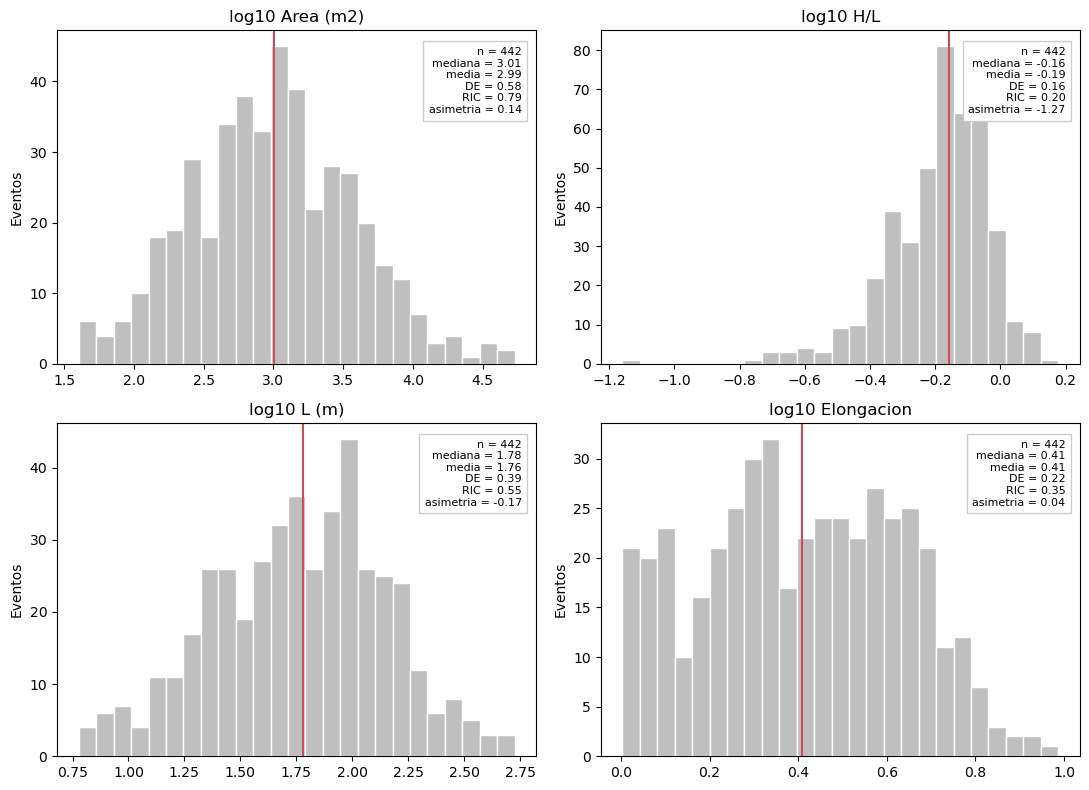

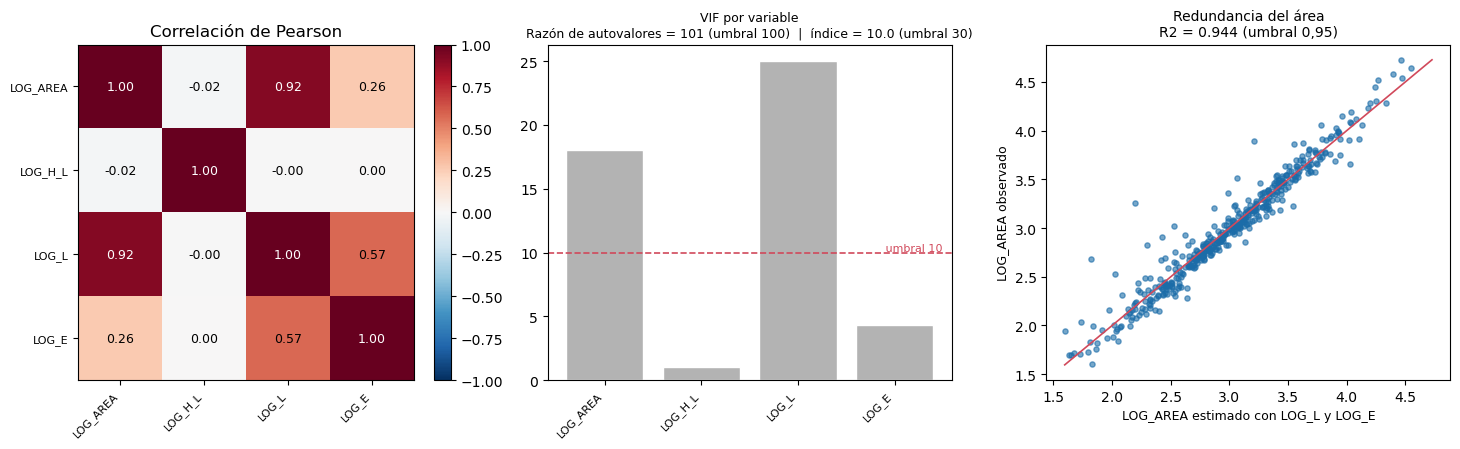

In [37]:
# Dibuja gráficos; viene instalada con ArcGIS Pro
import matplotlib.pyplot as plt
# Sirve para sellar el informe con la fecha y hora de esta ejecución
import datetime
 
# Capa cuya tabla de atributos se va a leer. "salida" es la copia del
# inventario que creó este mismo código en el BLOQUE 5
TABLA = salida
# Nombres de las columnas del vector, EN ESTE ORDEN:
# 0 = área, 1 = movilidad, 2 = distancia de viaje, 3 = elongación
VARS_VECTOR = ["LOG_AREA", "LOG_H_L", "LOG_L", "LOG_E"]
# Texto que se mostrará en el título de cada histograma
ETIQUETAS = {"LOG_AREA": "log10 Area (m2)", "LOG_H_L": "log10 H/L",
             "LOG_L": "log10 L (m)", "LOG_E": "log10 Elongacion"}
# Carpeta donde se guardan la figura y el informe (la que contiene la geodatabase)
CARPETA_FIGURAS = os.path.dirname(GDB_SALIDA)
 
# Lista de columnas que tiene ahora la capa de resultados
columnas_actuales = [f.name for f in arcpy.ListFields(TABLA)]
# Columnas del vector que todavía no existen
faltantes = [v for v in VARS_VECTOR if v not in columnas_actuales]
 
# Si falta alguna, avisa y no sigue con este bloque
if faltantes:
    print("\nFaltan las columnas", ", ".join(faltantes),
          "- calcula E y los logaritmos y vuelve a ejecutar solo este bloque.")
else:
    # Si existe la columna USAR, se respeta; si no, se usan los eventos con FLAG_MOV = OK
    filtro_usar = "USAR" in columnas_actuales
    # Columnas que se van a leer de la tabla
    leer = VARS_VECTOR + ["FLAG_MOV"] + (["USAR"] if filtro_usar else [])
    # Lista donde se guardan las filas que sirven
    valores = []
    # Recorre la tabla de resultados
    with arcpy.da.SearchCursor(TABLA, leer) as cursor:
        for fila in cursor:
            # Los cuatro valores del vector de este evento
            v = fila[:4]
            # Descarta el evento si algún valor está vacío
            if any(x is None for x in v):
                continue
            # Descarta el evento si su calidad no es OK
            if fila[4] != "OK":
                continue
            # Si hay columna USAR, descarta los eventos que no estén marcados con 1
            if filtro_usar and fila[5] != 1:
                continue
            # Guarda la fila como lista de números
            valores.append([float(x) for x in v])
 
    # Convierte todo en una tabla de números: una fila por evento, una columna por variable
    X = np.array(valores)
    # Avisa si quedaron muy pocos eventos para analizar
    if len(X) < 10:
        print("\nSolo quedaron", len(X), "eventos completos: revisa los filtros.")
    else:
        # ---- Estadísticos básicos de cada variable ----
        # Número de eventos
        n = len(X)
        # Media de cada columna
        media = X.mean(axis=0)
        # Desviación estándar de cada columna
        desv = X.std(axis=0, ddof=1)
        # Mediana de cada columna
        mediana = np.median(X, axis=0)
        # Cuartiles 25 y 75: entre ellos está la mitad central de los datos
        q1, q3 = np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)
        # Asimetría: 0 es simétrica, positiva = cola hacia la derecha
        asimetria = (((X - media) / X.std(axis=0)) ** 3).mean(axis=0)
 
        # ---- Figura con los cuatro histogramas ----
        # Crea una figura con 2 filas y 2 columnas de gráficos
        fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
        # Recorre cada variable junto con su gráfico
        for k, (eje, var) in enumerate(zip(ejes.ravel(), VARS_VECTOR)):
            # Dibuja el histograma con 25 barras
            eje.hist(X[:, k], bins=25, color="0.75", edgecolor="white")
            # Línea vertical en la mediana
            eje.axvline(mediana[k], color="#d1495b", linewidth=1.5)
            # Título del gráfico
            eje.set_title(ETIQUETAS.get(var, var))
            # Eje vertical: cuántos eventos hay en cada barra
            eje.set_ylabel("Eventos")
            # Texto con los estadísticos, en la esquina superior derecha
            eje.text(0.97, 0.95,
                     "n = %d\nmediana = %.2f\nmedia = %.2f\nDE = %.2f\nRIC = %.2f\nasimetria = %.2f"
                     % (n, mediana[k], media[k], desv[k], q3[k] - q1[k], asimetria[k]),
                     transform=eje.transAxes, ha="right", va="top", fontsize=8,
                     bbox=dict(facecolor="white", edgecolor="0.8"))
        # Ajusta los márgenes para que nada quede encimado
        fig.tight_layout()
        # Guarda la figura como imagen
        ruta_figura = os.path.join(CARPETA_FIGURAS, "fase1_histogramas.png")
        fig.savefig(ruta_figura, dpi=150)
 
        # ---- Revisión de colinealidad ----
        # Matriz de correlación de Pearson entre las cuatro variables
        R = np.corrcoef(X, rowvar=False)
        # Matriz de correlación de Spearman: la misma fórmula, pero sobre los rangos
        rangos = np.apply_along_axis(lambda c: np.argsort(np.argsort(c)) + 1, 0, X)
        R_s = np.corrcoef(rangos, rowvar=False)
        # VIF: cuánto se infla la varianza de cada variable por culpa de las otras
        VIF = np.diag(np.linalg.inv(R))
        # Autovalores de la matriz de correlación, de mayor a menor
        autoval = np.sort(np.linalg.eigvalsh(R))[::-1]
        # Razón entre el autovalor mayor y el menor: qué tan aplastada está la nube
        # Criterio: mayor que 100 = colinealidad notable; mayor que 1000 = severa
        razon_autoval = float(autoval[0] / autoval[-1])
        # Índice de condición: la raíz de esa razón. Criterio: mayor que 30 = severa
        indice_cond = float(np.sqrt(razon_autoval))
        # Porcentaje de la variación total que queda en la dirección más aplastada
        pct_plano = float(100 * autoval[-1] / autoval.sum())
 
        # Prueba directa: ¿el área queda determinada por L y la elongación?
        # (en un rectángulo ideal, log A = 2 log L - log E)
        # Posiciones dentro de VARS_VECTOR: 0 = área, 1 = movilidad,
        # 2 = distancia de viaje, 3 = elongación (funciona con cualquier nombre)
        i_a, i_l, i_e = 0, 2, 3
        # Matriz con una columna de unos (el intercepto), log L y log E
        M = np.column_stack([np.ones(n), X[:, i_l], X[:, i_e]])
        # Ajuste por mínimos cuadrados de log A en función de esas dos variables
        coef = np.linalg.lstsq(M, X[:, i_a], rcond=None)[0]
        # Parte de la variación de log A que NO explican L y E
        resid = X[:, i_a] - M @ coef
        # R²: fracción de la variación de log A explicada por L y E
        r2 = float(1 - (resid ** 2).sum() / ((X[:, i_a] - X[:, i_a].mean()) ** 2).sum())
 
        # ---- Informe en pantalla y en archivo ----
        def tabla_texto(M):
            """Convierte una matriz en texto con los nombres de las variables."""
            # Ancho fijo para que las columnas queden alineadas
            anchos = max(len(v) for v in VARS_VECTOR) + 2
            # Primera línea: los nombres de las columnas
            filas_txt = [" " * anchos + "".join(v.rjust(anchos) for v in VARS_VECTOR)]
            # Una línea por variable, con su nombre al inicio
            for i, v in enumerate(VARS_VECTOR):
                filas_txt.append(v.ljust(anchos)
                                 + "".join(("%.3f" % M[i, j]).rjust(anchos)
                                           for j in range(len(VARS_VECTOR))))
            # Une todas las líneas
            return "\n".join(filas_txt)
 
        # Arma el texto del informe línea por línea
        lineas_txt = ["=" * 60,
                      "FASE 1 - REVISIÓN DE COLINEALIDAD",
                      "=" * 60,
                      "Ejecutado: " + datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
                      "Tabla leída: " + str(TABLA),
                      "Variables: " + ", ".join(VARS_VECTOR),
                      "Eventos usados: %d" % n, "",
                      "CORRELACIÓN DE PEARSON (relación lineal, de -1 a 1):",
                      tabla_texto(R), "",
                      "CORRELACIÓN DE SPEARMAN (sobre los rangos):",
                      tabla_texto(R_s), "",
                      "VIF (mayor que 10 indica colinealidad fuerte):",
                      "  " + " | ".join("%s = %.2f" % (v, f) for v, f in zip(VARS_VECTOR, VIF)),
                      "",
                      "Autovalores: " + ", ".join("%.4f" % a for a in autoval),
                      "Razón de autovalores (mayor/menor): %.1f "
                      "(mayor que 100 es notable, mayor que 1000 es severa)" % razon_autoval,
                      "Índice de condición (su raíz): %.2f (mayor que 30 es severa)" % indice_cond,
                      "La dirección más aplastada retiene el %.2f %% de la variación" % pct_plano,
                      "",
                      "¿El área queda determinada por la distancia y la elongación?",
                      "  %s ~ %s + %s   R2 = %.4f (mayor que 0,95 es problema)"
                      % (VARS_VECTOR[i_a], VARS_VECTOR[i_l], VARS_VECTOR[i_e], r2),
                      "  intercepto = %.3f, coef. %s = %.3f, coef. %s = %.3f"
                      % (coef[0], VARS_VECTOR[i_l], coef[1], VARS_VECTOR[i_e], coef[2]),
                      "=" * 60]
        # Une las líneas en un solo texto
        informe = "\n".join(lineas_txt)
        # Lo muestra en pantalla
        print("\n" + informe)
        # Lo guarda en un archivo de texto
        ruta_informe = os.path.join(CARPETA_FIGURAS, "fase1_colinealidad.txt")
        with open(ruta_informe, "w", encoding="utf-8") as f:
            f.write(informe)
 
        # Avisa si la colinealidad es fuerte según cualquiera de los tres criterios
        if r2 > 0.95 or razon_autoval > 100 or VIF.max() > 10:
            print("\n>> Colinealidad fuerte entre área, distancia de viaje y elongación. "
                  "Llévale estos números al asesor antes de la Fase 3.")
 
        # ---- Figura de colinealidad: tres paneles ----
        # Crea una figura con tres gráficos en fila
        fig2, (p1, p2, p3) = plt.subplots(1, 3, figsize=(15, 4.6))
 
        # Panel 1: mapa de la matriz de correlación (azul = negativa, rojo = positiva)
        imagen = p1.imshow(R, vmin=-1, vmax=1, cmap="RdBu_r")
        # Nombres de las variables en los dos ejes
        p1.set_xticks(range(len(VARS_VECTOR)))
        p1.set_xticklabels(VARS_VECTOR, rotation=45, ha="right", fontsize=8)
        p1.set_yticks(range(len(VARS_VECTOR)))
        p1.set_yticklabels(VARS_VECTOR, fontsize=8)
        # Escribe el valor dentro de cada casilla
        for i in range(len(VARS_VECTOR)):
            for j in range(len(VARS_VECTOR)):
                p1.text(j, i, "%.2f" % R[i, j], ha="center", va="center", fontsize=9,
                        color="white" if abs(R[i, j]) > 0.6 else "black")
        # Título y barra de color
        p1.set_title("Correlación de Pearson")
        fig2.colorbar(imagen, ax=p1, fraction=0.046)
 
        # Panel 2: barras con el VIF de cada variable
        p2.bar(range(len(VARS_VECTOR)), VIF, color="0.7", edgecolor="white")
        # Línea roja en el umbral de 10
        p2.axhline(10, color="#d1495b", linestyle="--", linewidth=1.2)
        # Etiqueta de la línea
        p2.text(len(VARS_VECTOR) - 0.5, 10, " umbral 10", color="#d1495b",
                va="bottom", ha="right", fontsize=8)
        # Nombres de las variables debajo de cada barra
        p2.set_xticks(range(len(VARS_VECTOR)))
        p2.set_xticklabels(VARS_VECTOR, rotation=45, ha="right", fontsize=8)
        # Título con el número de condición del conjunto
        p2.set_title("VIF por variable\nRazón de autovalores = %.0f (umbral 100)  |  "
                     "índice = %.1f (umbral 30)" % (razon_autoval, indice_cond),
                     fontsize=9)
 
        # Panel 3: área observada frente a la estimada con distancia y elongación
        estimado = M @ coef
        # Cada punto es un evento
        p3.scatter(estimado, X[:, i_a], s=14, color="#1b6ca8", alpha=0.6)
        # Línea 1:1: si los puntos caen encima, el área es redundante
        limites = [min(estimado.min(), X[:, i_a].min()), max(estimado.max(), X[:, i_a].max())]
        p3.plot(limites, limites, color="#d1495b", linewidth=1.2)
        # Nombres de los ejes
        p3.set_xlabel("%s estimado con %s y %s" % (VARS_VECTOR[i_a], VARS_VECTOR[i_l],
                                                   VARS_VECTOR[i_e]), fontsize=9)
        p3.set_ylabel("%s observado" % VARS_VECTOR[i_a], fontsize=9)
        # Título con el R2 de ese ajuste
        p3.set_title("Redundancia del área\nR2 = %.3f (umbral 0,95)" % r2, fontsize=10)
 
        # Ajusta los márgenes y guarda la figura
        fig2.tight_layout()
        ruta_figura_col = os.path.join(CARPETA_FIGURAS, "fase1_colinealidad.png")
        fig2.savefig(ruta_figura_col, dpi=150)
 
        # Muestra dónde quedaron los tres archivos
        print("\nHistogramas:", ruta_figura)
        print("Figura de colinealidad:", ruta_figura_col)
        print("Informe:", ruta_informe)
 

# Verificación de los valores de la Tabla 2 y del texto

**¿Que hace?**

Lee los eventos OK y calcula los valores que se reportan en la Tabla 2 y en el texto de la tesis, escritos con coma decimal y punto de miles: la mediana, el mínimo y el máximo del área, del H/L, de L y de la elongación; la mediana de H; el rango del 50 % central del H/L con su ángulo de alcance, y los casos límite con desnivel o distancia muy pequeños. Solo lee la capa.

In [38]:


import numpy as np
import arcpy

# ---- Parámetros: ajusta los nombres si en tu tabla son distintos ----
TABLA_VERIF = TABLA          # la misma capa que leyó el Bloque 10
CAMPO_AREA  = "Shape_Area"      # nombre real de tu campo de área (m²)
CAMPO_HL    = "H_L"
CAMPO_L     = "L_M"
CAMPO_H     = "H_M"
CAMPO_E     = "E"

# ---- Lectura: solo eventos con las métricas completas ----
campos = [CAMPO_AREA, CAMPO_HL, CAMPO_L, CAMPO_H, CAMPO_E]
filas = [f for f in arcpy.da.SearchCursor(TABLA_VERIF, campos, "FLAG_MOV = 'OK'")
         if None not in f]
A, HL, L, H, E = (np.array(c, dtype=float) for c in zip(*filas))
print("Eventos leídos:", len(A), "(debe dar 442)\n")

# ---- Formato con coma decimal y punto de miles, como en la tesis ----
def es(x, dec):
    texto = f"{x:,.{dec}f}"                       # 53,356.0 -> formato inglés
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

# ---- Mediana, mínimo y máximo de cada variable ----
print(f"{'Variable':<12}{'Mediana':>12}{'Mínimo':>12}{'Máximo':>12}")
for nombre, v, dec in [("Área (m²)", A, 0), ("H/L", HL, 3),
                       ("L (m)", L, 1), ("Elongación", E, 2)]:
    print(f"{nombre:<12}{es(np.median(v), dec):>12}"
          f"{es(v.min(), dec):>12}{es(v.max(), dec):>12}")

# ---- Mediana del desnivel (va en el texto) ----
print(f"\nMediana de H: {es(np.median(H), 1)} m")

# ---- Cuartiles de H/L y su ángulo de alcance equivalente ----
q1, q3 = np.percentile(HL, [25, 75])
a1, a3 = np.degrees(np.arctan([q1, q3]))
print(f"50 % central de H/L: {es(q1, 2)} a {es(q3, 2)}"
      f"  ->  {a1:.0f}° a {a3:.0f}°")

# ---- Casos límite (dentro de los 442) ----
n_h = int((H < 2).sum())
n_l = int((L < 8).sum())
n_u = int(((H < 2) | (L < 8)).sum())
print(f"\nH < 2 m: {n_h} | L < 8 m: {n_l} | cualquiera de los dos: {n_u}")

# ---- Resolución del DEM (si la variable del Bloque 1 sigue cargada) ----
try:
    r = arcpy.Raster(MDE_RECORTADO)
    print(f"\nTamaño de celda del DEM: {r.meanCellWidth:.2f} m")
except NameError:
    print("\n(Ejecuta el Bloque 1 para ver el tamaño de celda del DEM)")

Eventos leídos: 442 (debe dar 442)

Variable         Mediana      Mínimo      Máximo
Área (m²)          1.012          40      53.356
H/L                0,696       0,069       1,505
L (m)               60,4         6,0       531,2
Elongación          2,56        1,01        9,70

Mediana de H: 44,1 m
50 % central de H/L: 0,53 a 0,83  ->  28° a 40°

H < 2 m: 2 | L < 8 m: 5 | cualquiera de los dos: 7

(Ejecuta el Bloque 1 para ver el tamaño de celda del DEM)


# Eventos excluidos, error de L y campo `USO_METRICAS`

**¿Que hace?**

Crea el campo `USO_METRICAS` que marca con 1, los eventos que usan las fases siguientes y con 0 los demás. También reúne los datos que justifican el umbral de 10 celdas: la lista de los 11 eventos excluidos, el error de L que produce el tamaño de celda del DEM y el número de eventos con medidas por fuente.


In [39]:

import numpy as np

CAMPO_AREA   = "Shape_Area"   # nombre real de tu campo de área
CAMPO_FUENTE = "fuente"    # nombre real de tu campo de fuente

# ---- Campo que marca qué eventos usan las fases siguientes (1 = sí) ----
arcpy.management.CalculateField(TABLA, "USO_METRICAS",
    "1 if !FLAG_MOV! == 'OK' else 0", "PYTHON3", field_type="SHORT")

# ---- Tamaño de celda del DEM ----
D = arcpy.Raster(DEM_POLIGONOS).meanCellWidth
print(f"Tamaño de celda: {D:.2f} m\n")

# ---- Los 11 excluidos: área, celdas y motivo ----
print("Eventos excluidos:")
for f in arcpy.da.SearchCursor(TABLA, [CAMPO_ID, CAMPO_AREA, "N_CELDAS", "FLAG_MOV"],
                               "FLAG_MOV <> 'OK'"):
    print(f"  ID {f[0]}: área {f[1]:.0f} m², {f[2]} celdas, {f[3]}")

# ---- Error relativo de L por discretización (sigma_L = D/raíz de 6) ----
L = np.array([f[0] for f in arcpy.da.SearchCursor(TABLA, ["L_M"], "FLAG_MOV = 'OK'")])
err = 100 * (D / np.sqrt(6)) / L
print(f"\nError relativo de L en el evento mediano: {np.median(err):.1f} %")
print(f"Error teórico con 10 celdas: {100 * 0.408 / np.sqrt(10):.1f} %")

# ---- Los 442 por fuente ----
print("\nEventos con métricas por fuente:")
for fuente in sorted({f[0] for f in arcpy.da.SearchCursor(TABLA, [CAMPO_FUENTE])}):
    n = sum(1 for _ in arcpy.da.SearchCursor(
        TABLA, [CAMPO_FUENTE], f"FLAG_MOV = 'OK' AND {CAMPO_FUENTE} = '{fuente}'"))
    print(f"  {fuente}: {n}")

Tamaño de celda: 2.00 m

Eventos excluidos:
  ID 56: área 24 m², 7 celdas, POCAS_CELDAS
  ID 75: área 36 m², 9 celdas, POCAS_CELDAS
  ID 93: área 17 m², 4 celdas, POCAS_CELDAS
  ID 109: área 34 m², 9 celdas, POCAS_CELDAS
  ID 222: área 669 m², 0 celdas, POCAS_CELDAS
  ID 360: área 2038 m², 0 celdas, POCAS_CELDAS
  ID 361: área 3817 m², 0 celdas, POCAS_CELDAS
  ID 362: área 1950 m², 0 celdas, POCAS_CELDAS
  ID 363: área 1721 m², 0 celdas, POCAS_CELDAS
  ID 364: área 4056 m², 408 celdas, REVISAR_RECORTE
  ID 440: área 30 m², 8 celdas, POCAS_CELDAS

Error relativo de L en el evento mediano: 1.4 %
Error teórico con 10 celdas: 12.9 %

Eventos con métricas por fuente:
  DAGRD: 45
  DAGRD (SIRE): 1
  DAGRD Medellín: 4
  DRAGAN: 2
  Fotointerpretación: 44
  Geohazards: 15
  Propia (GoogleEarth): 173
  Propia (PlanetScope): 122
  SIATA: 26
  SIMMA: 6
  SIRMED: 4
